In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator, SymmetricalLogLocator
import seaborn as sns
from IPython.display import display

In [2]:
TASK = Path.cwd().parent
ROOT = TASK.parent
INPUT, OUTPUT = TASK/'input', TASK/'output'
CONFIG = json.loads((ROOT/'config.json').read_text())
Y, SEED = CONFIG['last_year'], CONFIG['seed']
WINDOW = 'last_four'
WINDOW_LABELS = {'last_four':f'Final four years ({Y-3}–{Y})', 'career_total':f'Whole career (0–{Y})'}
SELECTED = ['empirical_complete', 'lognormal_grw', 'ar1_s', 'hurdle_ar1_s_p', 'se_hurdle_s']
LABELS = {'empirical_complete':'DBLP empirical', 'lognormal_grw':'GRW', 'ar1_s':'AR(1)',
          'hurdle_ar1_s_p':'Hurdle AR(1)', 'se_hurdle_s':'Self-exciting hurdle'}
palette = sns.color_palette('colorblind')
COLORS = dict(zip(SELECTED, ['#222222', palette[0], palette[1], palette[4], palette[2]]))
LINES = dict(zip(SELECTED, ['-', '--', '-.', ':', '-']))
MARKERS = dict(zip(SELECTED, ['o', 's', '^', 'D', 'v']))
sns.set_theme(style='ticks', context='paper', font_scale=1,
              rc={'font.size':8, 'axes.labelsize':8, 'axes.titlesize':9,
                  'xtick.labelsize':7, 'ytick.labelsize':7, 'legend.fontsize':8,
                  'pdf.fonttype':42, 'ps.fonttype':42, 'savefig.dpi':400})

In [3]:
qq_windows = pd.read_csv(INPUT/'window_qq_points.csv')
qq_windows = qq_windows.loc[qq_windows.source.isin(SELECTED) & qq_windows.window.isin([WINDOW,'career_total'])].copy()
qq = qq_windows.loc[qq_windows.window.eq(WINDOW)].copy()
lognormality = pd.read_csv(INPUT/'lognormality_summary.csv')
lognormality = lognormality.loc[lognormality.source.isin(SELECTED)].copy()
ranks = pd.read_csv(INPUT/'rank_mixing.csv')
ranks = ranks.loc[ranks.source.isin(SELECTED) & ranks.measure.eq('annual') & ranks.reference.eq('lag_5')].copy()
comparison = pd.read_csv(INPUT/'model_comparison.csv').set_index('source').loc[SELECTED]
cdf_windows = pd.read_csv(INPUT/'distribution_cdf.csv')
cdf_windows = cdf_windows.loc[cdf_windows.source.isin(SELECTED) & cdf_windows.diagnostic.isin([WINDOW,'career_total'])].copy()
cdf_knots = cdf_windows.loc[cdf_windows.diagnostic.eq(WINDOW)].copy()

In [4]:
# exact ECDFs from the same four-year sums as the QQ; no pooled annual observations
panel = pd.read_csv(INPUT/'simulation/fit/data/panel_complete.csv', index_col='dblp_id')
arrays = {'empirical_complete':panel.to_numpy(dtype=float).T}
for tag in SELECTED[1:]:
    arrays[tag] = np.load(INPUT/'simulation'/tag/'trajectories.npy', mmap_mode='r')
total_frames = {}
for window,start in [(WINDOW,Y-3),('career_total',0)]:
    total_frames[window] = pd.concat([pd.DataFrame({'source':tag, 'total':array[start:Y+1].sum(axis=0)})
                                    for tag,array in arrays.items()], ignore_index=True)

In [5]:
# primary numeric summary and explicit whole-career supplement; no individual records exported
summary = lognormality.loc[lognormality.window.eq(WINDOW)].set_index('source').loc[SELECTED].copy()
summary['final_zero_fraction'] = comparison.final_zero_fraction
summary['lag_5_rho20'] = comparison.lag_5_rho20
summary['career_total_qq_r2'] = lognormality.loc[lognormality.window.eq('career_total')].set_index('source').qq_r2
summary['label'] = pd.Series(LABELS)
summary.to_csv(OUTPUT/'pnas_model_summary.csv')
qq.to_csv(OUTPUT/'pnas_model_qq_points.csv', index=False)
ranks.to_csv(OUTPUT/'pnas_model_lag5.csv', index=False)
cdf_knots.to_csv(OUTPUT/'pnas_model_ecdf_knots.csv', index=False)
lognormality.loc[lognormality.window.eq('career_total')].to_csv(OUTPUT/'pnas_career_total_summary.csv', index=False)
qq_windows.loc[qq_windows.window.eq('career_total')].to_csv(OUTPUT/'pnas_career_total_qq_points.csv', index=False)
cdf_windows.loc[cdf_windows.diagnostic.eq('career_total')].to_csv(OUTPUT/'pnas_career_total_ecdf_knots.csv', index=False)
display(summary)

,window,role,start_age,end_age,n_total,n_positive,n_zero,zero_fraction,mean_total,gini_total,loc,fit_scale,qq_r,qq_r2,ks_D,prefix_included,final_zero_fraction,lag_5_rho20,career_total_qq_r2,label
source,,,,,,,,,,,,,,,,,,,,
empirical_complete,last_four,primary,17,20,510,500,10,0.019608,28.127164,0.467120,4.240414,1.441332,0.987660,0.975473,0.060820,False,0.141176,0.582696,0.991906,DBLP empirical
lognormal_grw,last_four,primary,17,20,10000,9825,175,0.017500,41454.510583,0.991900,5.608451,4.650150,0.991900,0.983866,0.045595,False,0.109500,0.741913,0.957396,GRW
ar1_s,last_four,primary,17,20,10000,9999,1,0.000100,27.947797,0.507315,4.089933,1.507395,0.995776,0.991569,0.023438,False,0.025000,0.100119,0.999467,AR(1)
hurdle_ar1_s_p,last_four,primary,17,20,10000,9855,145,0.014500,25.129366,0.447935,4.072660,1.529635,0.965536,0.932259,0.079963,False,0.156600,0.136052,0.987290,Hurdle AR(1)
se_hurdle_s,last_four,primary,17,20,10000,9741,259,0.025900,28.800348,0.460437,4.306557,1.418203,0.986538,0.973258,0.058832,False,0.143400,0.553039,0.967322,Self-exciting hurdle


In [6]:
def draw_qq(ax, window=WINDOW):
    points = qq_windows.loc[qq_windows.window.eq(window)]
    for tag in SELECTED:
        data = points.loc[points.source.eq(tag)].sort_values('normal_quantile')
        sns.lineplot(data=data, x='normal_quantile', y='observed_quantile', ax=ax,
                     color=COLORS[tag], linestyle=LINES[tag], marker=MARKERS[tag],
                     markevery=50, markersize=2.5, linewidth=1.1, estimator=None, errorbar=None, legend=False)
    limits = (points.normal_quantile.min(), points.normal_quantile.max())
    ax.plot(limits, limits, color='.6', linewidth=.7, zorder=0)
    ax.set(title=WINDOW_LABELS[window]+' shape', xlabel='Standard normal quantile',
           ylabel='Standardized log-total quantile')
    ax.xaxis.set_major_locator(MaxNLocator(4))
    ax.yaxis.set_major_locator(MaxNLocator(5))
    sns.despine(ax=ax)
def draw_ecdf(ax, window=WINDOW):
    for tag in SELECTED:
        sns.ecdfplot(data=total_frames[window].loc[total_frames[window].source.eq(tag)], x='total', ax=ax,
                     color=COLORS[tag], linestyle=LINES[tag], linewidth=1.2, legend=False)
    # shared scale and full tails; linear segment preserves the mass at zero
    ax.set_xscale('symlog', linthresh=1, linscale=.5, base=10)
    ax.set_xlim(left=0)
    locator = SymmetricalLogLocator(base=10,linthresh=1)
    locator.set_params(numticks=4)
    upper = ax.get_xlim()[1]
    ax.set_xticks([value for value in locator.tick_values(0,upper) if value==0 or 1<value<=upper])
    ax.set(title=WINDOW_LABELS[window]+' scale', xlabel='Four-year total output' if window==WINDOW else 'Career-total output',
           ylabel='Cumulative probability', ylim=(0,1.02), yticks=[0,.25,.5,.75,1])
    ax.text(.98, .05, 'Log scale above 1', transform=ax.transAxes, ha='right', fontsize=6.5)
    sns.despine(ax=ax)
def draw_rank(ax):
    for tag in SELECTED:
        data = ranks.loc[ranks.source.eq(tag)].sort_values('age')
        sns.lineplot(data=data, x='age', y='rho', ax=ax, color=COLORS[tag],
                     linestyle=LINES[tag], marker=MARKERS[tag], markevery=3,
                     markersize=3, linewidth=1.2, estimator=None, errorbar=None, legend=False)
    ax.set(title='Annual rank memory', xlabel='Career year, $t$',
           ylabel=r'Spearman $\rho_S(R_{t-5},R_t)$',
           xlim=(ranks.age.min(),ranks.age.max()), ylim=(-.05,1.05))
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=4))
    ax.yaxis.set_major_locator(MaxNLocator(5))
    sns.despine(ax=ax)
def legend_handles():
    return [Line2D([], [], color=COLORS[tag], linestyle=LINES[tag], marker=MARKERS[tag],
                   markersize=3, linewidth=1.2, label=LABELS[tag]) for tag in SELECTED]
def save_figure(fig, stem):
    for extension in ['pdf','png']:
        fig.savefig(OUTPUT/f'{stem}.{extension}', bbox_inches='tight', facecolor='white')

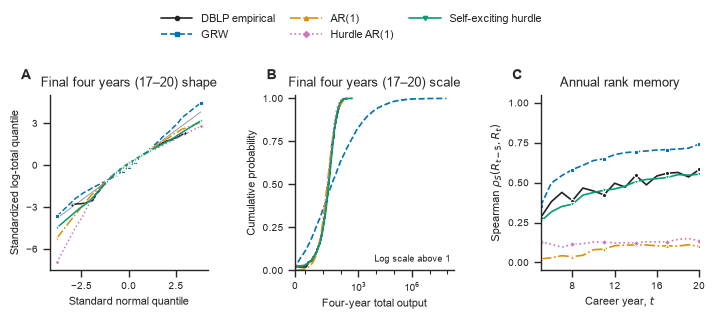

In [7]:
# primary manuscript composite; shared legend above the panels
fig, axes = plt.subplots(1,3,figsize=(7.1,3.25))
for letter,draw,ax in zip('ABC',[draw_qq,draw_ecdf,draw_rank],axes):
    draw(ax)
    ax.text(-.18,1.09,letter,transform=ax.transAxes,weight='bold',fontsize=10)
fig.legend(handles=legend_handles(),loc='upper center',ncol=3,frameon=False,
           bbox_to_anchor=(.5,1.01),columnspacing=1.4,handlelength=2.8)
fig.subplots_adjust(left=.075,right=.99,bottom=.19,top=.73,wspace=.55)
save_figure(fig,'pnas_dblp_model_comparison')
plt.show()
plt.close(fig)

In [8]:
# individual panels for alternative manuscript layouts
for name,draw in [('qq',draw_qq),('ecdf',draw_ecdf),('lag5',draw_rank)]:
    fig,ax = plt.subplots(figsize=(3.5,3.3))
    draw(ax)
    fig.legend(handles=legend_handles(),loc='upper center',ncol=2,frameon=False,
               bbox_to_anchor=(.5,1.01),handlelength=2.8)
    fig.subplots_adjust(left=.20,right=.96,bottom=.17,top=.70)
    save_figure(fig,f'pnas_dblp_{name}')
    plt.close(fig)

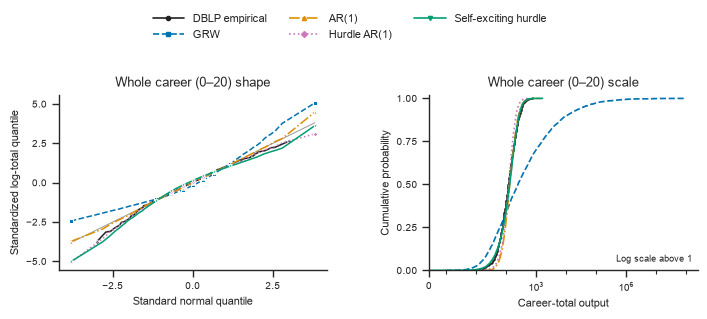

In [9]:
# retain the previous whole-career distribution view as an explicit supplement
fig,axes = plt.subplots(1,2,figsize=(7.1,3.25))
draw_qq(axes[0],window='career_total')
draw_ecdf(axes[1],window='career_total')
fig.legend(handles=legend_handles(),loc='upper center',ncol=3,frameon=False,
           bbox_to_anchor=(.5,1.01),handlelength=2.8)
fig.subplots_adjust(left=.09,right=.99,bottom=.19,top=.73,wspace=.38)
save_figure(fig,'pnas_dblp_career_total_supplement')
plt.show()
plt.close(fig)

In [10]:
# aggregation, zero handling and cohort stated alongside the figure
n_empirical = int(summary.loc['empirical_complete','n_total'])
n_simulated = int(summary.loc['lognormal_grw','n_total'])
caption = (
    r'\textbf{Four-year distributional shape and temporal agreement of DBLP productivity models.} '
    f'Empirical comparisons use {n_empirical:,} complete publication histories over career years '
    f'0--{Y}; each model generates {n_simulated:,} histories. '
    f'Panels A and B use the sum of annual adjusted productivity over the final four career years, '
    f'{Y-3}--{Y}, matching Shockley\'s four-year aggregation. '
    r'(A) Normal QQ curves of positive four-year totals after taking $\log_2$ and standardizing '
    r'each source separately to zero mean and unit sample standard deviation. '
    r'The grey diagonal is the normal reference. Standardization removes location and scale; '
    r'zero totals are excluded only from this panel and their counts are reported separately. '
    r'QQ curves retain up to 401 ordered points, including the extremes; reported QQ $R^2$ uses all positive totals. '
    r'(B) Exact empirical cumulative distribution functions of the same four-year totals, including zeros '
    r'and full tails. The shared output axis is linear from zero to one and logarithmic above one. '
    r'(C) Spearman correlation of annual productivity ranks five years apart, with average ranks for ties. '
    r'The same complete empirical cohort is used at every year. '
    r'Models share colors and line styles across panels. These are in-sample generative checks. '
    r'The self-exciting hurdle model is fitted to complete histories; the other models use available '
    r'adjacent-year observations. Whole-career QQ and ECDF views are retained in a separate supplement.'
)
(OUTPUT/'pnas_dblp_model_comparison_caption.tex').write_text(caption+'\n')
supplement_caption = (
    r'\textbf{Whole-career distributional supplement.} '
    f'QQ and exact ECDF views use totals over career years 0--{Y}. '
    r'Cohorts, standardization, zero handling and display conventions match the primary four-year figure.'
)
(OUTPUT/'pnas_dblp_career_total_supplement_caption.tex').write_text(supplement_caption+'\n')
display(pd.DataFrame({'file':['pnas_dblp_model_comparison.pdf','pnas_dblp_career_total_supplement.pdf',
                             'pnas_model_summary.csv','pnas_career_total_summary.csv'],
                      'purpose':['primary four-year figure','whole-career supplement',
                                 'primary numeric summary','whole-career numeric summary']}))

,file,purpose
0,pnas_dblp_model_comparison.pdf,primary four-year figure
1,pnas_dblp_career_total_supplement.pdf,whole-career supplement
2,pnas_model_summary.csv,primary numeric summary
3,pnas_career_total_summary.csv,whole-career numeric summary
